<a href="https://colab.research.google.com/github/SariChiba/El_Turismo_Esta_De_Vuelta/blob/ileana/notebook/turismo_datacenter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---

# Análisis de turismo no residente en Argentina
---


## _Análisis inicial_
###### Lo primero que vamos a hacer es importar las librerías que vamos a necesitar para poder ejecutar correctamente el notebook.



In [280]:
import pandas as pd #para manipular los archivos
import matplotlib.pyplot as plt #para hacer gráficos
import seaborn as sb #para hacer gráficos
import geopandas as gdp #facilita la creación de gráficos y mapas visuales usando datos geográficos
import numpy as np #para realizar operaciones matemáticas

In [281]:
#Vamos a cargar el dataset elegido a través de una url
url = 'https://raw.githubusercontent.com/SariChiba/El_Turismo_Esta_De_Vuelta/main/dataset/turistas-no-residentes-serie.csv'

#A continuación, le pedimos a pandas que lo lea y le asignamos un nombre para crear el dataframe
turismo = pd.read_csv(url)

#Ahora vamos a ver el dataframe que acabamos de crear
turismo

,indice_tiempo,medio_de_transporte,pais_origen,viajes_de_turistas_no_residentes,observaciones
0,2010-01-01,Aérea,Bolivia,4390,NaN
1,2010-01-01,Aérea,Brasil,72669,NaN
2,2010-01-01,Aérea,Chile,14726,NaN
3,2010-01-01,Aérea,Paraguay,4062,NaN
4,2010-01-01,Aérea,Uruguay,3512,NaN
...,...,...,...,...,...
5395,2026-08-01,Terrestre,Uruguay,27147,Dato provisorio
5396,2026-08-01,Terrestre,EE.UU. y Canadá,2268,Dato provisorio
5397,2026-08-01,Terrestre,Resto de América,8320,Dato provisorio
5398,2026-08-01,Terrestre,Europa,12908,Dato provisorio


In [282]:
#Mostramos las primeras filas de nuestro dataframe con la ayuda de .head(10)
turismo.head(10)

,indice_tiempo,medio_de_transporte,pais_origen,viajes_de_turistas_no_residentes,observaciones
0,2010-01-01,Aérea,Bolivia,4390,NaN
1,2010-01-01,Aérea,Brasil,72669,NaN
2,2010-01-01,Aérea,Chile,14726,NaN
3,2010-01-01,Aérea,Paraguay,4062,NaN
4,2010-01-01,Aérea,Uruguay,3512,NaN
5,2010-01-01,Aérea,EE.UU. y Canadá,42783,NaN
6,2010-01-01,Aérea,Resto de América,36410,NaN
7,2010-01-01,Aérea,Europa,75995,NaN
8,2010-01-01,Aérea,Resto del mundo,15212,NaN
9,2010-01-01,Fluvial/Marítima,Bolivia,2304,NaN


In [283]:
#Mostramos las últimas filas usando .tail, también seleccionamos 10
turismo.tail(10)

,indice_tiempo,medio_de_transporte,pais_origen,viajes_de_turistas_no_residentes,observaciones
5390,2026-08-01,Fluvial/Marítima,Resto del mundo,1228,Dato provisorio
5391,2026-08-01,Terrestre,Bolivia,7336,Dato provisorio
5392,2026-08-01,Terrestre,Brasil,34488,Dato provisorio
5393,2026-08-01,Terrestre,Chile,10373,Dato provisorio
5394,2026-08-01,Terrestre,Paraguay,25351,Dato provisorio
5395,2026-08-01,Terrestre,Uruguay,27147,Dato provisorio
5396,2026-08-01,Terrestre,EE.UU. y Canadá,2268,Dato provisorio
5397,2026-08-01,Terrestre,Resto de América,8320,Dato provisorio
5398,2026-08-01,Terrestre,Europa,12908,Dato provisorio
5399,2026-08-01,Terrestre,Resto del mundo,2251,Dato provisorio


A continuación, decidimos eliminar la columna ```observaciones``` porque consideramos que no aporta datos de importancia en nuestro análisis, ya que nuestra investigación se centra en la evolución temporal, los países de origen y el impacto de la pandemia.


⚠️ Importante
---
Utilizamos la ayuda de la _**IA**_ y el apoyo de los apuntes de la materia para definir una función que elimine la columna sin romper ni provocar daños en el df.

> _Prompt utilizado: Eliminar la columna 'observaciones' de un DataFrame de pandas de forma permanente (inplace)_

###### → ¿Qué es _**inplace**_?
Quiere decir que el cambio que estamos realizando va a ser en nuestro dataframe original y no en una copia.


In [284]:
# Definimos una función que recibe un DataFrame y el nombre de la columna a eliminar
def eliminar_columna(df, columna):
    if columna in df.columns:
        df.drop(columns=[columna], inplace=True)
        print(f"Columna '{columna}' eliminada exitosamente.")
    else:
        print(f"La columna '{columna}' no existe en el DataFrame.")

eliminar_columna(turismo, 'observaciones')

#Volvemos a utilizar .head para verificar cómo quedó nuestro df sin la columna eliminada
turismo.head()

Columna 'observaciones' eliminada exitosamente.


,indice_tiempo,medio_de_transporte,pais_origen,viajes_de_turistas_no_residentes
0,2010-01-01,Aérea,Bolivia,4390
1,2010-01-01,Aérea,Brasil,72669
2,2010-01-01,Aérea,Chile,14726
3,2010-01-01,Aérea,Paraguay,4062
4,2010-01-01,Aérea,Uruguay,3512


In [285]:
#Inspeccionamos el archivo con la función info
#ACLARACIÓN: unas celdas mas adelante hacemos una inspección más detallada y limpia, pero el .info() nos da un pantallazo inicial bastante más rápido

turismo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5400 entries, 0 to 5399
Data columns (total 4 columns):
 #   Column                            Non-Null Count  Dtype 
---  ------                            --------------  ----- 
 0   indice_tiempo                     5400 non-null   object
 1   medio_de_transporte               5400 non-null   object
 2   pais_origen                       5400 non-null   object
 3   viajes_de_turistas_no_residentes  5400 non-null   int64 
dtypes: int64(1), object(3)
memory usage: 168.9+ KB


Ahora, vamos a realizar otra modificación que consideramos importante, porque estamos trabajando principalmente con períodos de tiempo y es necesario que Pandas reconozca las fechas como tal, así que convertimos ```indice_tiempo``` a datetime.

In [286]:
turismo['indice_tiempo'] = pd.to_datetime(turismo['indice_tiempo'])

#Volvemos a utilizar .info para verificar si ahora la columna indice_tiempo es reconocida como datetime
turismo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5400 entries, 0 to 5399
Data columns (total 4 columns):
 #   Column                            Non-Null Count  Dtype         
---  ------                            --------------  -----         
 0   indice_tiempo                     5400 non-null   datetime64[ns]
 1   medio_de_transporte               5400 non-null   object        
 2   pais_origen                       5400 non-null   object        
 3   viajes_de_turistas_no_residentes  5400 non-null   int64         
dtypes: datetime64[ns](1), int64(1), object(2)
memory usage: 168.9+ KB


In [287]:
#Pedimos que chequee si hay valores nulos
turismo.isnull().sum()

,0
indice_tiempo,0
medio_de_transporte,0
pais_origen,0
viajes_de_turistas_no_residentes,0


En este caso, nos devulve ```0``` en todas las filas porque no tenemos valores nulos.

In [288]:
#Aplicamos .duplicated para revisar si hay filas duplicadas
turismo.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
5395,False
5396,False
5397,False
5398,False


Nos parece relevante aclarar que podríamos haber utilizado ```turismo.duplicated().sum()``` para obtener el mismo resultado, pero la diferencia con el que finalmente utilizamos es debido a la forma en que se mostraba el resultado.

```turismo.duplicated().sum()``` nos devuelve solamente ```np.int64(0)```, en lugar de un cuadro. Nos parece mejor y más llamativa la opción finalmente utilizada, aunque con ambos obtengamos el mismo resultado: **no hay duplicados en este dataframe.**
---

En la siguiente celda vamos a realizar lo restante del análisis inicial de forma más limpia. Es importante aclarar que vamos a utilizar ```exclude="datetime"``` al usar ```.describe``` para que no nos dé métricas sin sentido sobre las fechas.

In [289]:
print("Dimensiones:", turismo.shape)
print("Columnas :", list(turismo.columns))
print("\nTipos de dato:")
print(turismo.dtypes)

print("\nPeríodo que cubre:", turismo["indice_tiempo"].min().date(), "→", turismo["indice_tiempo"].max().date())

cantidad_visitantes_total = turismo['viajes_de_turistas_no_residentes'].sum()
print(f"\nCantidad total de visitantes no residentes: {cantidad_visitantes_total: ,.0f}")

turismo.describe(exclude="datetime").round(2)

Dimensiones: (5400, 4)
Columnas : ['indice_tiempo', 'medio_de_transporte', 'pais_origen', 'viajes_de_turistas_no_residentes']

Tipos de dato:
indice_tiempo                       datetime64[ns]
medio_de_transporte                         object
pais_origen                                 object
viajes_de_turistas_no_residentes             int64
dtype: object

Período que cubre: 2010-01-01 → 2026-08-01

Cantidad total de visitantes no residentes:  97,999,975


,medio_de_transporte,pais_origen,viajes_de_turistas_no_residentes
count,5400,5400,5400.00
unique,3,9,NaN
top,Aérea,Bolivia,NaN
freq,1800,600,NaN
mean,NaN,NaN,18148.14
std,NaN,NaN,21317.76
min,NaN,NaN,0.00
25%,NaN,NaN,3325.00
50%,NaN,NaN,9184.00
75%,NaN,NaN,27894.75


¿Por qué aparecen los NaN?

Las métricas como unique, top y freq solo aplican a texto y no se calculan para números, entonces para la columna de ```viajes_de_turistas_no_residentes``` se muestra NaN.
Las métricas como mean (promedio), std (desviación estándar), min, max y los percentiles solo aplican a números y no se pueden calcular para texto, entonces para ```medios_de_transporte``` y ```pais_origen``` se muestra NaN.



### ¿Qué podemos concluir de este análisis inicial?
Tenemos 5400 entradas de datos sobre las que trabajar. Estas filas se dividen en ```indice_tiempo```, ```medio_de_transporte```,	```pais_origen``` y 	```viajes_de_turistas_no_residentes```.

Sobre la columna ```medio_de_transporte``` vamos a poder analizar la forma de llegar al país, en ```pais_origen``` tenemos el país de dónde provienen y su última columna,	```viajes_de_turistas_no_residentes```, nos da los números reales de la cantidad de turistas recibidos en un período de tiempo definido en ```indice_tiempo```.

Por otro lado, un dato interesante que podemos obtener del último cuadro realizado con ```.describe``` es el promedio para los viajes, que nos indica que la cantidad promedio de viajes para cada mes de los 16 años que recorre este dataframe es **18148**. Un número no tan grande a simple vista, pero puede verse afectado porque tenemos la pandemia de COVID-19 en el medio, donde hay meses sin viajes registrados o muy pocos.


# _Pregunta de investigación_

---

> ## **¿Cómo evolucionó el turismo no residente en Argentina en los últimos 16 años?**

La principal motivación para realizar el análisis de la evolución del turismo en nuestro país es guíada por la pandemia de COVID-19, donde uno de los sectores más afectados, durante el aislamiento, y al que más trabajo le costó recuperarse, cuando todo se fue abriendo nuevamente de manera paulatina, fue al sector de Turismo.

Uno de nuestros objetivos, más allá de realizar el análisis de manera exitosa, es poder plasmar de una manera bastante clara en este notebook: comparaciones de la cantidad de viajes entre los años previos y posteriores a la pandemia, además clasificar comparaciones por países y medios de transporte. Es decir, realizar un análisis gráfico y textual que pueda entenderse sin problemas.


A continuación, empezamos con el análisis gráfico de lo que hasta ahora se planteó con palabras.

⚠️ Importante
---
Utilizamos la ayuda de la _**IA**_ para utilizar el punto como separación de los miles y que el cuadro sea más fácil de leer.

> _Prompt utilizado: Utilizar el punto como separación de los miles en la cantidad de visitas total de cada año._

In [290]:
#Obtenemos la cantidad de visitantes no residentes por año
#Creamos la columna "año" utilizando el tipo datetime ya convertido al inicio del análisis inicial, utilizamos .dt.year para extraer solo el año
turismo['anio'] = turismo['indice_tiempo'].dt.year

#Sumamos los viajes de todos los meses, países y transportes de cada año
visitas_por_anio = turismo.groupby('anio')['viajes_de_turistas_no_residentes'].sum().reset_index()

#Renombrar las columnas para la presentación
visitas_por_anio.columns = ['Año', 'Cantidad de visitas']

#Pedimos ayuda a la IA para crear una copia formateada visualmente con puntos como separadores de miles
visitas_por_anio_formateado = visitas_por_anio.copy()
visitas_por_anio_formateado['Cantidad de visitas'] = visitas_por_anio_formateado['Cantidad de visitas'].map(lambda x: f"{x:,.0f}".replace(",", "."))

#Mostramos los resultados con el formato de lectura mejorado
visitas_por_anio_formateado

,Año,Cantidad de visitas
0,2010,6.738.593
1,2011,6.674.029
2,2012,6.461.769
3,2013,6.510.286
4,2014,7.165.219
5,2015,6.815.623
6,2016,6.668.207
7,2017,6.711.248
8,2018,6.941.767
9,2019,7.398.973


En este cuadro agrupamos la cantidad de visitantes totales diferenciada por año. Podemos ver la gran diferencia con 2020 y 2021 debido a la pandemia de COVID-19; siendo 2021 el año más afectado por las limitaciones.

> **TENER EN CUENTA:**
El año 2026 solo posee datos hasta agosto, por lo que su resultado no está completo por ahora, solo estamos viendo el resultado de 8 meses de turismo frente a los 12 meses completos de 2010 a 2025. Aunque podemos ver a simple vista que con solo 8 meses, 2026 está muy cerca de lo que fue el año completo de 2025.

In [291]:
#Obtenemos el año con mayor cantidad de visitantes:

anio_max_visitas = visitas_por_anio.loc[visitas_por_anio['Cantidad de visitas'].idxmax()]

print(f"El año con mayor cantidad de visitantes fue {anio_max_visitas['Año']} con {anio_max_visitas['Cantidad de visitas']: ,.0f} visitas.")

El año con mayor cantidad de visitantes fue 2019 con  7,398,973 visitas.


---

La siguiente celda va a contener un gráfico para que sea vea mejor la diferencia de turistas en cada año.

⚠️ Importante
---
Utilizamos la ayuda de la _**IA**_ y el apoyo de los apuntes de la materia para crear un gráfico de barras que represente la cantidad de visitas por año.

> _Prompt utilizado: Crear gráfico de barras que contenga la cantidad de visitas por año, utilizando un punto como separación de los miles._

Algunas líneas de código de la IA fueron corregidoas por el equipo para que se parezcan más a los códigos aprendidos en clase.

---

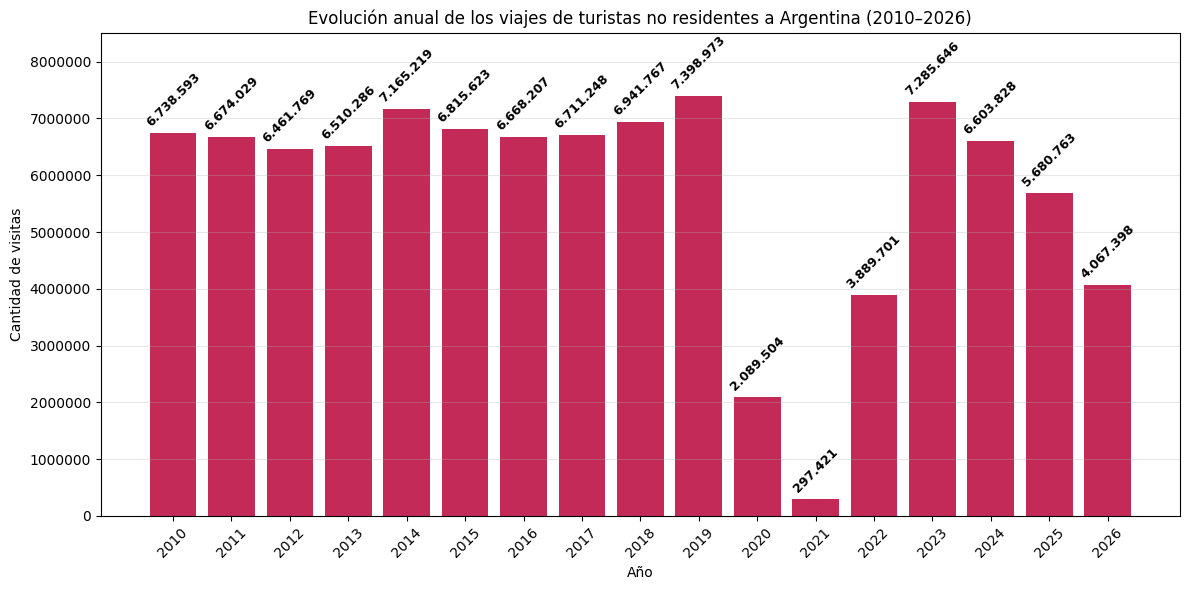

In [292]:
#Vamos a utilizar un gráfico de barras
fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.bar(visitas_por_anio['Año'], visitas_por_anio['Cantidad de visitas'], width=0.8, color='#C42A57')

#Se crea la separación con punto para los miles
etiquetas_formateadas = [f"{int(valor):,}".replace(",", ".") for valor in visitas_por_anio['Cantidad de visitas']]

#Añadimos los valores numéricos sobre cada columna con estilo negrita (weight='bold')
ax.bar_label(bars, labels=etiquetas_formateadas, padding=3, rotation=45, fontsize=9, weight='bold')

plt.title('Evolución anual de los viajes de turistas no residentes a Argentina (2010–2026)')
plt.xlabel('Año')
plt.ylabel('Cantidad de visitas')
plt.xticks(visitas_por_anio['Año'], rotation=45)

#Ajustamos el límite de "y" para que las etiquetas no se corten
plt.ylim(0, visitas_por_anio['Cantidad de visitas'].max() * 1.15)

plt.ticklabel_format(axis="y", style="plain")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

#Vamos a guardar el gráfico para usar en el informe y presentación
plt.savefig("Evolución anual de los viajes de turistas no residentes a Argentina (2010–2026).png")


plt.show()

### ¿Cómo interpretamos los resultados?

El gráfico muestra la evolución de la cantidad de viajes de turistas no residentes en Argentina entre 2010 y 2026. Durante el período 2010-2019, se observa un comportamiento relativamente estable, con fluctuaciones moderadas y un máximo de casi 7,4 millones de viajes alcanzado en 2019.

En 2020 y 2021 se registra una disminución significativa, coincidente con la pandemia de COVID-19 y las restricciones de los viajes internacionales. Los 2 millones de personas que se registran en 2020 son de los primero tres meses del año, antes de que se restringieran los viajes por completo. Y el año 2021 fue el más afectado.

A partir de 2022 se evidencia una recuperación del turismo, alcanzando en 2023 valores cercanos a los registrados antes de la pandemia. Sin embargo, durante 2024 y 2025 se observa una nueva tendencia descendente. Aún hoy, los números siguen sin poder acercarse al años 2019, donde se registró la mayor cantidad de turistas en los 16 años que estamos analizando.

_Es importante señalar que los datos correspondientes a 2026 abarcan únicamente hasta agosto, por lo que no pueden compararse directamente con los años completos._

---
#### **¿Qué países o regiones aportaron más turistas durante el periodo analizado?**


Calculamos la cantidad de viajes por país o región. Los datos son más específicos para los países limitrofes, para el resto del mundo se agrupa por región.

Primero agrupamos los datos por pais_origen y sumamos la cantidad de viajes registrados.

In [293]:
#Agrupamos por país/región, los sumamos y ordenamos de mayor a menor
visitas_por_pais = turismo.groupby('pais_origen')['viajes_de_turistas_no_residentes'].sum().sort_values(ascending=False)

# Calcular el porcentaje de visitas de cada país/región respecto al total general
visitas_total_general = visitas_por_pais.sum()
porcentaje_por_pais = (visitas_por_pais / visitas_total_general) * 100

# Crear un DataFrame para mostrar los resultados con formato
# Formateamos la cantidad de visitas con puntos como separador de miles y el porcentaje con '%'
tabla_porcentajes = pd.DataFrame({
    'Cantidad de visitas': visitas_por_pais.map(lambda x: f"{x:,.0f}".replace(",", ".")),
    'Porcentaje (%)': porcentaje_por_pais.round(2).map('{:.2f}%'.format)
})

display(tabla_porcentajes)

,Cantidad de visitas,Porcentaje (%)
pais_origen,,
Brasil,19.206.027,19.60%
Chile,15.868.607,16.19%
Europa,13.424.077,13.70%
Uruguay,12.917.528,13.18%
Paraguay,10.885.956,11.11%
Resto de América,9.241.591,9.43%
EE.UU. y Canadá,7.144.982,7.29%
Bolivia,5.517.186,5.63%
Resto del mundo,3.794.021,3.87%


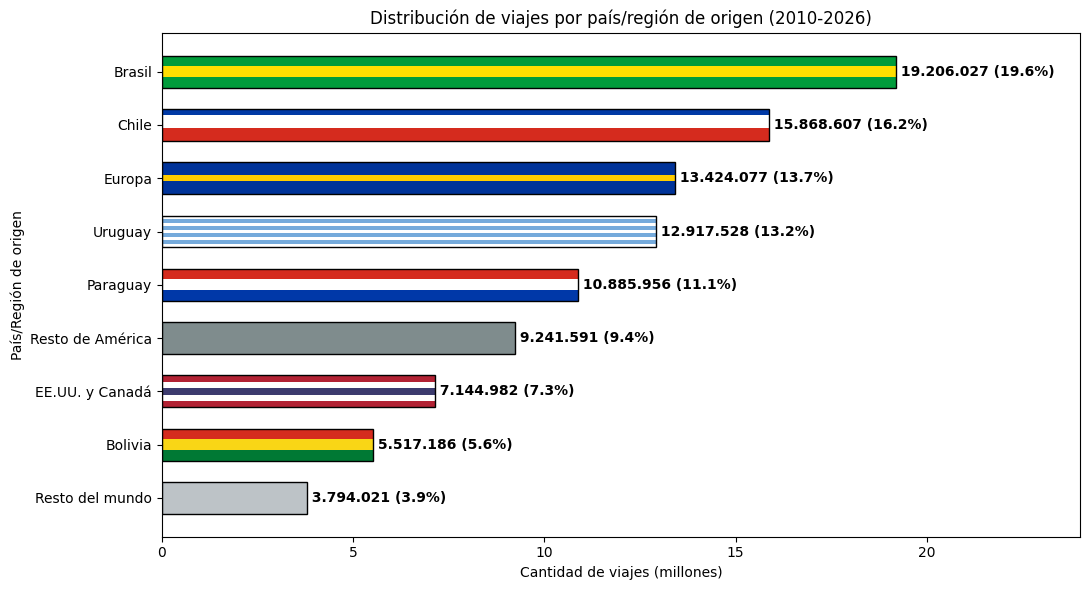

In [294]:
#Con ayuda de la IA, creamos un gráfico de barras basado en la tabla de países de origen.
#El prompt utilizado fue "Realizar un gráfico de barras horizontal, en el cuál cada barra sea de los colores de la bandera del país/región representado"

from matplotlib.ticker import FuncFormatter
import matplotlib.pyplot as plt

# Colores de cada bandera, de arriba hacia abajo (una franja por color)
banderas = {
    'Brasil': ['#009C3B', '#FFDF00', '#009C3B'],
    'Chile': ['#0039A6', '#FFFFFF', '#D52B1E'],
    'Europa': ['#003399', '#003399', '#FFCC00', '#003399', '#003399'],
    'Uruguay': ['#FFFFFF', '#75AADB'] * 4 + ['#FFFFFF'],
    'Paraguay': ['#D52B1E', '#FFFFFF', '#0038A8'],
    'Bolivia': ['#D52B1E', '#F9D616', '#007934'],
    'EE.UU. y Canadá': ['#B22234', '#FFFFFF', '#3C3B6E', '#FFFFFF', '#B22234'],
    'Resto de América': ['#7F8C8D'],
    'Resto del mundo': ['#BDC3C7']
}

visitas_por_pais = turismo.groupby('pais_origen')['viajes_de_turistas_no_residentes'].sum().sort_values(ascending=True)
porcentajes = visitas_por_pais / visitas_por_pais.sum() * 100
fig, ax = plt.subplots(figsize=(11, 6))
alto = 0.6
pesos = {'Chile': [0.5, 1, 1]}

for i, (pais, valor) in enumerate(visitas_por_pais.items()):
    franjas = banderas[pais]
    p = pesos.get(pais, [1] * len(franjas))
    y_tope = i + alto / 2
    for color, peso in zip(franjas, p):
        alto_franja = alto * peso / sum(p)
        ax.barh(y_tope - alto_franja / 2, valor, height=alto_franja, color=color, edgecolor='none')
        y_tope -= alto_franja
    ax.barh(i, valor, height=alto, fill=False, edgecolor='black', linewidth=1.0)
    texto = f" {valor:,.0f} ({porcentajes[pais]:.1f}%)".replace(",", ".")
    ax.text(valor, i, texto, va='center', fontweight='bold')

ax.set_yticks(range(len(visitas_por_pais)))
ax.set_yticklabels(visitas_por_pais.index)
ax.set_title('Distribución de viajes por país/región de origen (2010-2026)')
ax.set_xlabel('Cantidad de viajes (millones)')
ax.set_ylabel('País/Región de origen')
ax.set_xlim(0, visitas_por_pais.max() * 1.25)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x/1e6:.0f}"))
plt.tight_layout()
plt.savefig('viajes_por_origen_banderas.png', dpi=300)
plt.show()

In [295]:
!pip install -q geopandas

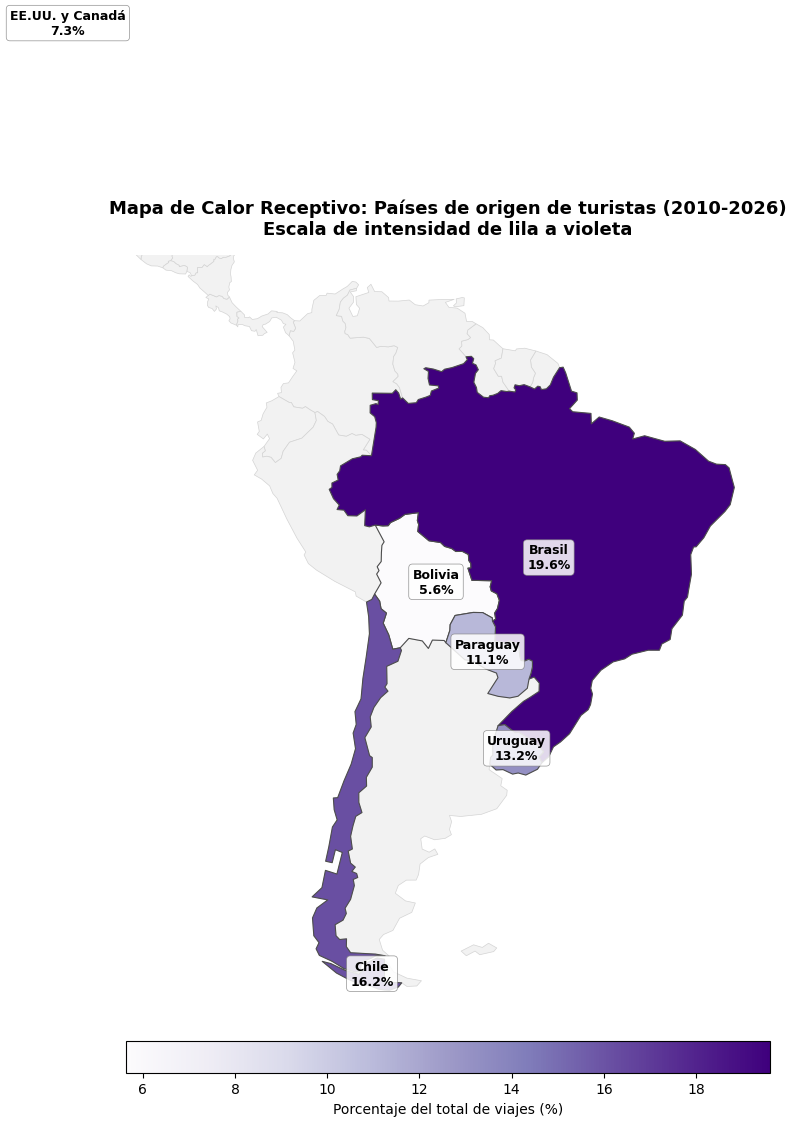

In [296]:
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 1. Agrupamos y obtenemos el total de los viajes para calcular porcentajes
visitas_por_pais = turismo.groupby('pais_origen')['viajes_de_turistas_no_residentes'].sum().reset_index()
total_viajes = visitas_por_pais['viajes_de_turistas_no_residentes'].sum()
visitas_por_pais['porcentaje'] = (visitas_por_pais['viajes_de_turistas_no_residentes'] / total_viajes) * 100

# 2. Descargamos un GeoJSON confiable y público del mapa del mundo desde GitHub para evitar el error de licencia de geopandas
geojson_url = "https://raw.githubusercontent.com/johan/world.geo.json/master/countries.geo.json"
world = gpd.read_file(geojson_url)

# 3. Homologamos los nombres de los países del mapa para que coincidan con tu dataset 'turismo'
mapeo_nombres = {
    'Brasil': 'Brazil',
    'Chile': 'Chile',
    'Uruguay': 'Uruguay',
    'Paraguay': 'Paraguay',
    'Bolivia': 'Bolivia',
    'EE.UU. y Canadá': 'United States of America'  # Mapeamos EEUU como referencia principal
}
visitas_por_pais['name_map'] = visitas_por_pais['pais_origen'].map(mapeo_nombres)

# 4. Unimos los datos geográficos con las estadísticas de turismo de Argentina
mapa_datos = world.merge(visitas_por_pais, left_on='name', right_on='name_map', how='left')

# 5. Delimitamos geográficamente la zona de América Latina y del Sur usando límites de coordenadas
fig, ax = plt.subplots(figsize=(10, 12))

# Dibujamos todo el continente de fondo en un color gris claro neutro
world.plot(ax=ax, color='#f2f2f2', edgecolor='#d4d4d4', linewidth=0.5)

# Pintamos solo los países que tienen datos asignados usando la escala de violetas
mapa_datos_con_datos = mapa_datos[mapa_datos['name_map'].notna()]

mapa_datos_con_datos.plot(
    column='porcentaje',
    cmap='Purples',
    linewidth=0.8,
    ax=ax,
    edgecolor='#4d4d4d',
    legend=True,
    legend_kwds={
        'label': "Porcentaje del total de viajes (%)",
        'orientation': "horizontal",
        'pad': 0.05,
        'shrink': 0.7
    }
)

# 6. Agregamos etiquetas informativas con el nombre y porcentaje de cada país emisor de turismo
for idx, row in mapa_datos_con_datos.iterrows():
    # Calculamos el punto representativo dentro de la geometría de cada país
    centroide = row['geometry'].representative_point()
    x, y = centroide.x, centroide.y

    # Un pequeño ajuste visual para mover la etiqueta de Brasil más a la izquierda para que no se superponga
    if row['pais_origen'] == 'Brasil':
        x -= 3

    ax.text(
        x, y,
        f"{row['pais_origen']}\n{row['porcentaje']:.1f}%",
        fontsize=9,
        weight='bold',
        ha='center',
        va='center',
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", lw=0.5, alpha=0.85)
    )

# Ajustamos los límites de la visualización del mapa para enfocar América Central y del Sur
ax.set_xlim([-95, -30])
ax.set_ylim([-56, 15])

# Título y formato final libre de ejes cartesianos
plt.title("Mapa de Calor Receptivo: Países de origen de turistas (2010-2026)\nEscala de intensidad de lila a violeta", fontsize=13, pad=15, weight='bold')
ax.set_axis_off()

plt.tight_layout()
plt.show()

Se observa que Brasil ocupa el primer lugar, seguido por Chile, Europa, Uruguay y Paraguay.

Estos resultados muestran la importancia de los países limítrofes como mercados emisores de turismo hacia Argentina.

El análisis permite concluir que existe una participación destacada de los países vecinos en el turismo receptivo argentino.

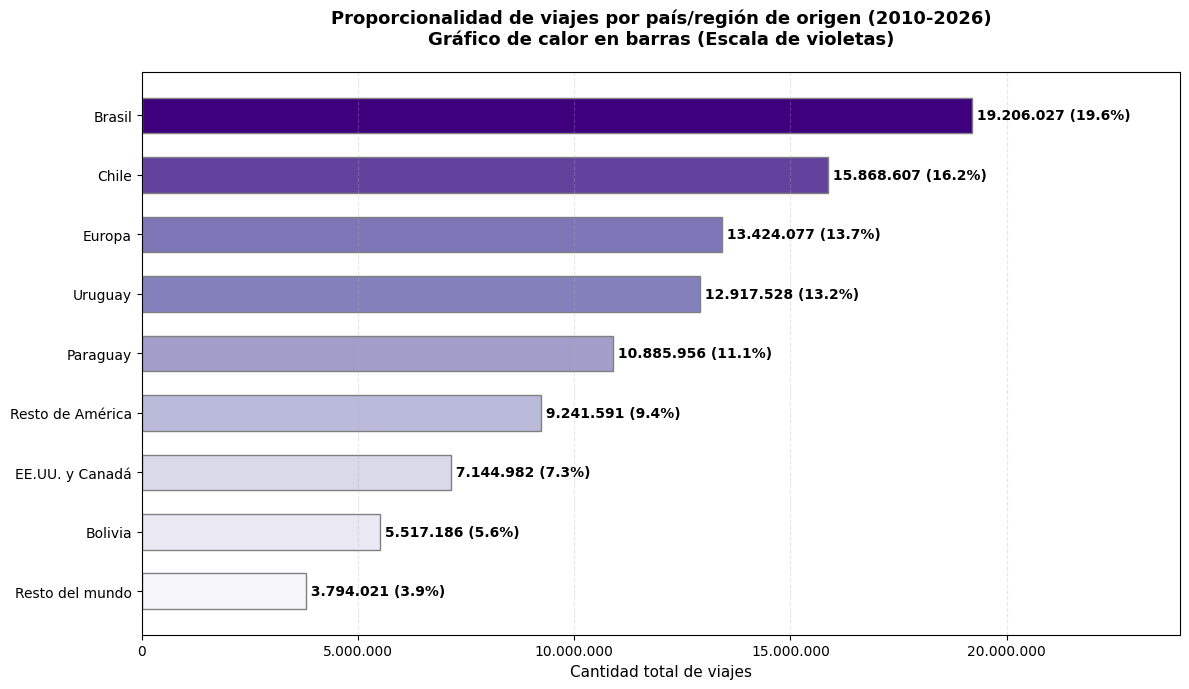

In [297]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np

# Agrupamos y ordenamos los datos de menor a mayor para el gráfico de barras
visitas_por_pais = turismo.groupby('pais_origen')['viajes_de_turistas_no_residentes'].sum().sort_values(ascending=True)
valores = visitas_por_pais.values
etiquetas = visitas_por_pais.index

# Calculamos los porcentajes
total_viajes = valores.sum()
porcentajes = (valores / total_viajes) * 100

# Creamos una escala de colores de violeta claro (lila) a violeta oscuro ('Purples')
normalizacion = plt.Normalize(vmin=valores.min() * 0.8, vmax=valores.max())
colores_violeta = cm.Purples(normalizacion(valores))

plt.figure(figsize=(12, 7))

# Dibujamos las barras horizontales con el degradado de calor
barras = plt.barh(
    etiquetas,
    valores,
    color=colores_violeta,
    edgecolor='grey',
    height=0.6
)

# Agregamos las etiquetas de texto al final de cada barra con formato argentino (puntos para miles)
for barra, porcentaje, valor in zip(barras, porcentajes, valores):
    ancho_barra = barra.get_width()
    texto_etiqueta = f" {valor:,.0f} ({porcentaje:.1f}%)".replace(",", ".")
    plt.text(
        ancho_barra,
        barra.get_y() + barra.get_height()/2,
        texto_etiqueta,
        va='center',
        ha='left',
        fontsize=10,
        weight='bold'
    )

# Diseño estético y moderno
plt.title("Proporcionalidad de viajes por país/región de origen (2010-2026)\nGráfico de calor en barras (Escala de violetas)", fontsize=13, pad=20, weight='bold')
plt.xlabel("Cantidad total de viajes", fontsize=11)
plt.xlim(0, valores.max() * 1.25)

# Eje X con separador de miles en puntos
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"{int(x):,}".replace(",", ".")))

plt.grid(axis='x', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

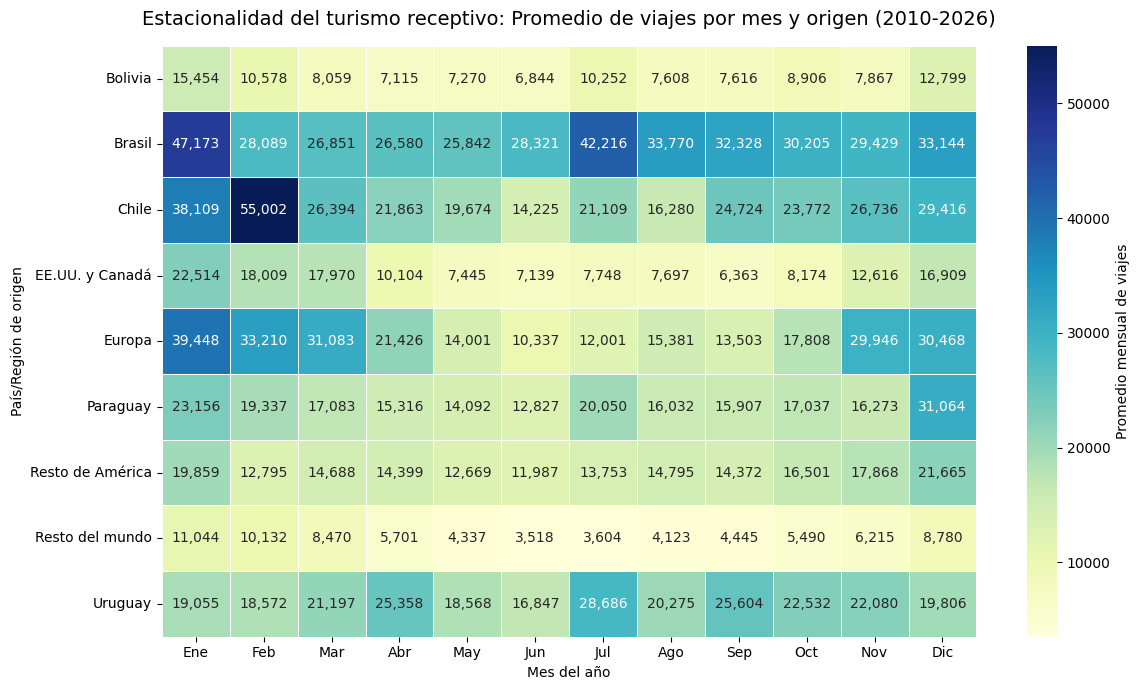

In [298]:
import seaborn as sns
import matplotlib.pyplot as plt

# Extraemos el mes directamente de 'indice_tiempo' para agrupar sin depender de una columna externa
heatmap_data = turismo.groupby(['pais_origen', turismo['indice_tiempo'].dt.month])['viajes_de_turistas_no_residentes'].mean().unstack()

# Mapeamos los números de mes a nombres cortos
heatmap_data.columns = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']

plt.figure(figsize=(12, 7))
sns.heatmap(
    heatmap_data,
    cmap='YlGnBu',
    annot=True,
    fmt=",.0f",
    linewidths=0.5,
    cbar_kws={'label': 'Promedio mensual de viajes'}
)

plt.title('Estacionalidad del turismo receptivo: Promedio de viajes por mes y origen (2010-2026)', fontsize=14, pad=15)
plt.xlabel('Mes del año')
plt.ylabel('País/Región de origen')
plt.tight_layout()
plt.show()

---
### **En el análisis anterior, se observa una caída muy marcada y una posterior recuperación entre el periodo 2019 y 2023 en el marco de la Pandemia COVID-19 que nos lleva a profundizar nuestro análisis:**

Calculamos cuánto disminuyó el turismo entre 2019 y 2023:

In [299]:
# Primero definimos 'viajes_pandemia' a partir de 'visitas_por_anio' para el rango 2019-2023
# Filtramos los años de interés y establecemos el Año como índice
viajes_pandemia = visitas_por_anio[
    (visitas_por_anio['Año'] >= 2019) & (visitas_por_anio['Año'] <= 2023)
].set_index('Año')['Cantidad de visitas']

# Tomar 2019 como referencia
viajes_2019 = viajes_pandemia.loc[2019]

# Calcular variación respecto a 2019
variacion = (
    (viajes_pandemia / viajes_2019) - 1
) * 100

print("Variación respecto a 2019:")
variacion.round(2).map("{:+.2f}%".format)

Variación respecto a 2019:


,Cantidad de visitas
Año,
2019,+0.00%
2020,-71.76%
2021,-95.98%
2022,-47.43%
2023,-1.53%


### **Impacto de la pandemia en el turismo no residente en Argentina**

El análisis de los viajes de turistas no residentes entre 2019 y 2023 evidencia una fuerte disminución durante los años de la pandemia de COVID-19.

En 2019 se registraron aproximadamente 7,4 millones de viajes, mientras que en 2020 esta cifra descendió a 2,1 millones. La caída se profundizó en 2021, cuando se alcanzó un mínimo de aproximadamente 297 mil viajes, equivalente a una disminución del 96% respecto de 2019.

Durante 2022 se observó una recuperación significativa, con aproximadamente 3,9 millones de viajes registrados. Sin embargo, esta cifra todavía se encontraba un 47,4% por debajo del nivel previo a la pandemia.

En 2023, los viajes alcanzaron aproximadamente 7,3 millones, acercándose a los valores de 2019.

Estos resultados muestran una fuerte ruptura en la evolución del turismo receptivo argentino durante la pandemia y una recuperación progresiva en los años posteriores. Aunque la caída coincide temporalmente con las restricciones a la movilidad internacional, los datos analizados por sí solos no permiten determinar cuánto de esa disminución fue causado por cada factor.

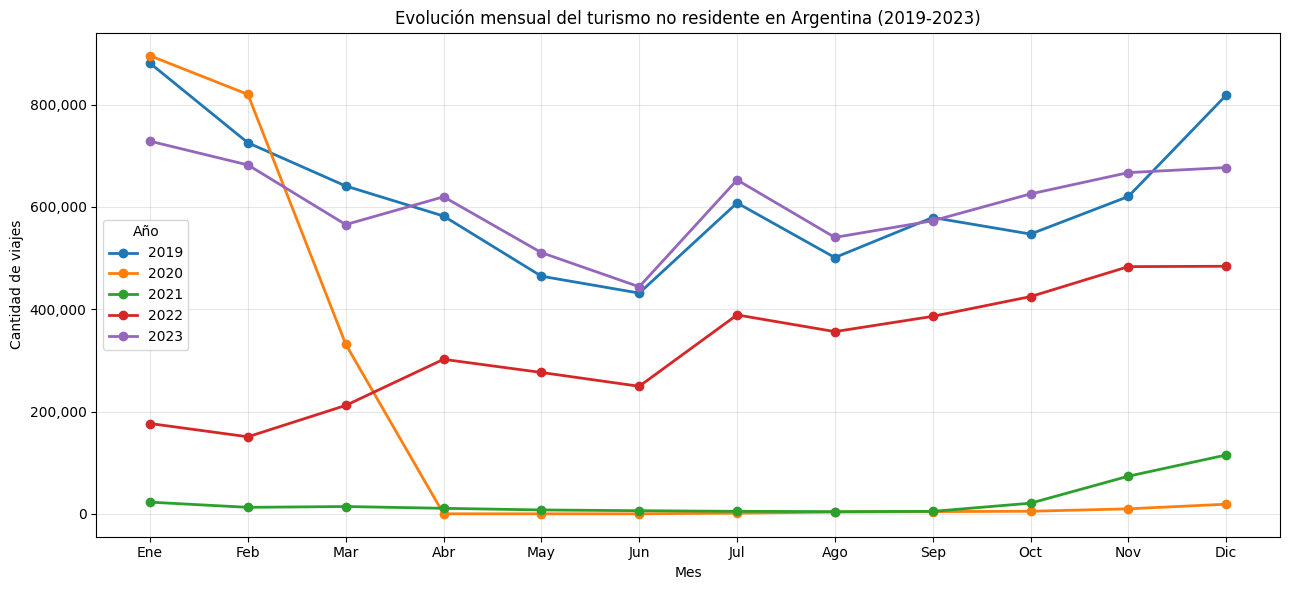

In [300]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Como 'indice_tiempo' ya es datetime, creamos/aseguramos las columnas de año y mes de forma directa
turismo["anio"] = turismo["indice_tiempo"].dt.year
turismo["mes"] = turismo["indice_tiempo"].dt.month

# Filtrar los años de interés
datos = turismo[turismo["anio"].between(2019, 2023)]

# Agrupar viajes por mes y año
comparacion = (
    datos.groupby(["mes", "anio"])[
        "viajes_de_turistas_no_residentes"
    ]
    .sum()
    .unstack()
)

# Crear gráfico
plt.figure(figsize=(13, 6))

for anio in comparacion.columns:
    plt.plot(
        comparacion.index,
        comparacion[anio],
        marker="o",
        linewidth=2,
        label=str(anio)
    )

plt.title(
    "Evolución mensual del turismo no residente "
    "en Argentina (2019-2023)"
)

plt.xlabel("Mes")
plt.ylabel("Cantidad de viajes")

plt.xticks(
    range(1, 13),
    ["Ene", "Feb", "Mar", "Abr", "May", "Jun",
     "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
)

plt.gca().yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x:,.0f}")
)

plt.legend(title="Año")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("lineas_superpuestas_pandemia.png", dpi=300)
plt.show()


Cada línea representa un año diferente, y cada punto muestra los viajes registrados durante un mes.

De esta manera, podemos comparar cómo se comportó el turismo en un mismo mes durante distintos años.

### Relación entre el mes del año y la cantidad de viajes turísticos

El gráfico de líneas superpuestas permite analizar la relación entre el mes del año y la cantidad de viajes de turistas no residentes a Argentina, comparando el comportamiento de esta variable entre 2019 y 2023.

La utilización de líneas diferenciadas por año permite identificar cambios en la evolución mensual del turismo durante la pandemia y su posterior recuperación.

La comparación con 2019, considerado como período de referencia previo a la pandemia, permite evaluar la magnitud de la disminución registrada en 2020 y 2021, así como el grado de recuperación observado durante 2022 y 2023.

Además, el análisis permite investigar la existencia de patrones estacionales y determinar si el comportamiento mensual del turismo recuperó características similares a las observadas antes de la pandemia.

### ¿Qué país de origen se recuperaron más rapido y cuáles todavía no?
#### Para compararlos usamos como base 2019 = 100 para cada origen. Un valor de 100 significa que el origen igualó su nivel al de 2019, y menos de 100 que sigue por debajo. Los datos del año 2016 solo llegan hasta agosto, por eso se compara con enero-agosto 2019.  

In [301]:
por_origen = turismo.pivot_table(index='pais_origen', columns='anio', values='viajes_de_turistas_no_residentes', aggfunc='sum')

indice = (por_origen[[2022, 2023, 2024, 2025]].div(por_origen[2019], axis=0) * 100).round(0)

ene_ago = turismo[turismo['mes'] <= 8].pivot_table(index='pais_origen', columns='anio', values='viajes_de_turistas_no_residentes', aggfunc='sum')
indice['Ene-Ago 2026'] = (ene_ago[2026] / ene_ago[2019] * 100).round(0)

indice = indice.sort_values('Ene-Ago 2026', ascending=False)
display(indice)

anio,2022,2023,2024,2025,Ene-Ago 2026
pais_origen,,,,,
EE.UU. y Canadá,66.0,115.0,117.0,105.0,121.0
Resto de América,52.0,93.0,107.0,97.0,115.0
Uruguay,95.0,189.0,125.0,95.0,100.0
Europa,47.0,79.0,85.0,87.0,93.0
Brasil,54.0,94.0,101.0,80.0,91.0
Resto del mundo,24.0,54.0,67.0,76.0,84.0
Chile,43.0,118.0,87.0,65.0,72.0
Paraguay,48.0,66.0,55.0,53.0,54.0
Bolivia,28.0,44.0,34.0,30.0,28.0


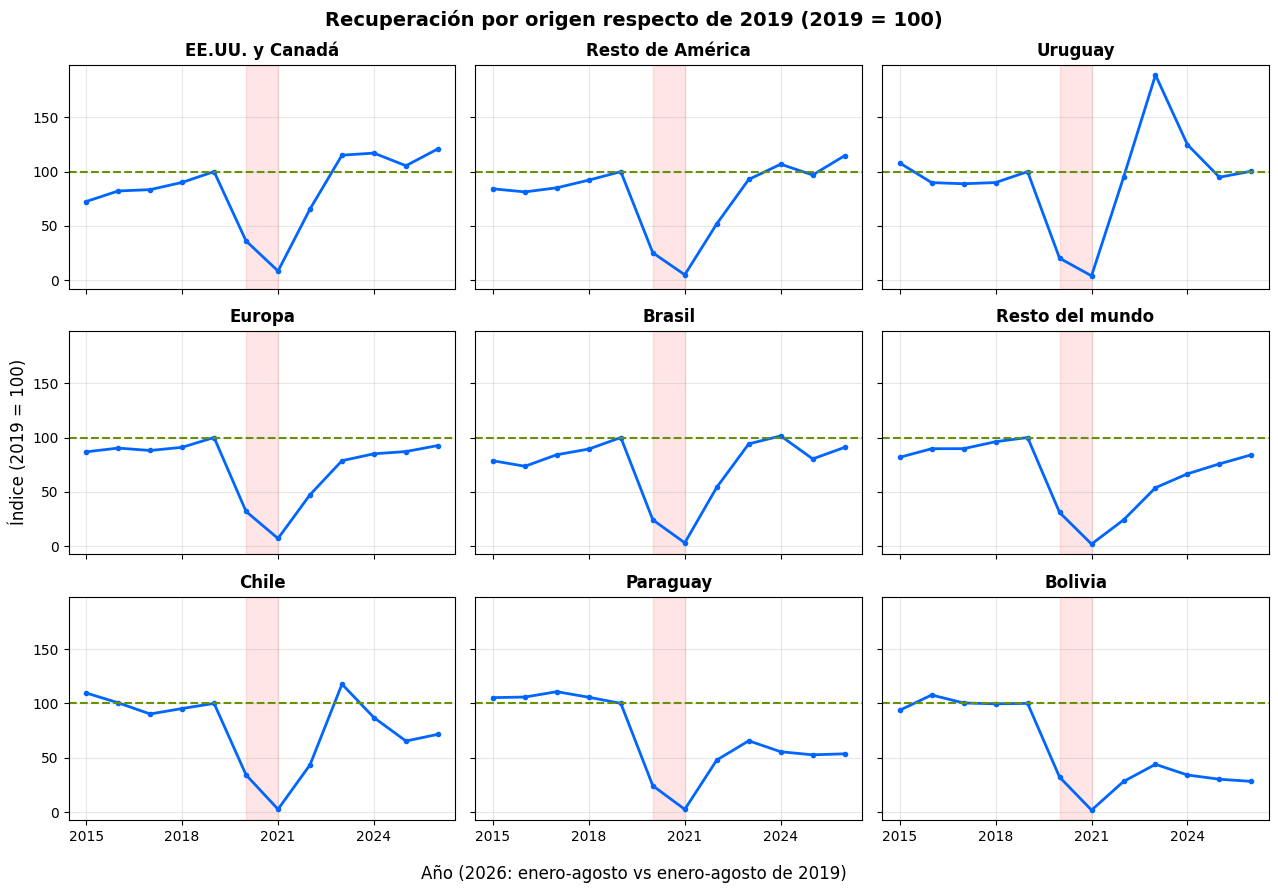

In [302]:
# Creamos un mini gráfico de lineas por origen y recuperación.

# 1) Índice 2019 = 100 por año y origen
por_origen = turismo.pivot_table(index='anio', columns='pais_origen', values='viajes_de_turistas_no_residentes', aggfunc='sum')
indice_anual = por_origen.div(por_origen.loc[2019]) * 100

# 2) 2026 solo llega hasta agosto: se compara contra enero-agosto de 2019
ene_ago = turismo[turismo['mes'] <= 8].pivot_table(index='anio', columns='pais_origen', values='viajes_de_turistas_no_residentes', aggfunc='sum')
indice_anual.loc[2026] = ene_ago.loc[2026] / ene_ago.loc[2019] * 100

# 3) Nos quedamos con 2015-2026 y ordenamos los orígenes por su nivel actual
indice_anual = indice_anual.loc[2015:2026]
orden = indice_anual.loc[2026].sort_values(ascending=False).index

# 4) Grilla de 3 x 3 paneles con los mismos ejes
fig, axes = plt.subplots(3, 3, figsize=(13, 9), sharex=True, sharey=True)
for ax, origen in zip(axes.flatten(), orden):
    ax.plot(indice_anual.index, indice_anual[origen], color='#0066FF', linewidth=2, marker='o', markersize=3)
    ax.axhline(100, color='#689000', linestyle='--')
    ax.axvspan(2020, 2021, color='red', alpha=0.1)
    ax.set_title(origen, fontweight='bold')
    ax.set_xticks(range(2015, 2027, 3))
    ax.grid(alpha=0.3)

fig.suptitle('Recuperación por origen respecto de 2019 (2019 = 100)', fontsize=14, fontweight='bold')
fig.supxlabel('Año (2026: enero-agosto vs enero-agosto de 2019)')
fig.supylabel('Índice (2019 = 100)')
plt.tight_layout()
plt.savefig('recuperacion_por_origen_lineas.png', dpi=300)
plt.show()

#### Lectura del gráfico:
##### La línea punteada verde es el nivel de 2019. Si la línea azul está por encima, el origen superó 2019, y si está por debajo, no se recuperó.
##### La franja roja marca 2020-2021 (pandemia).
##### Los paneles están ordenados del origen que mejor se recuperó (arriba a la izquierda) al que menos (abajo a la derecha).

#Comparación entre transportes ✈️ 🚢 🚍

medio_de_transporte,Aérea,Terrestre,Fluvial/Marítima
anio,,,
2010,41.6,43.1,15.3
2011,42.8,42.0,15.2
2012,42.2,42.7,15.1
2013,38.9,45.0,16.1
2014,36.4,49.7,13.9
2015,35.6,49.7,14.7
2016,35.8,49.0,15.1
2017,38.2,46.5,15.2
2018,39.8,45.4,14.8


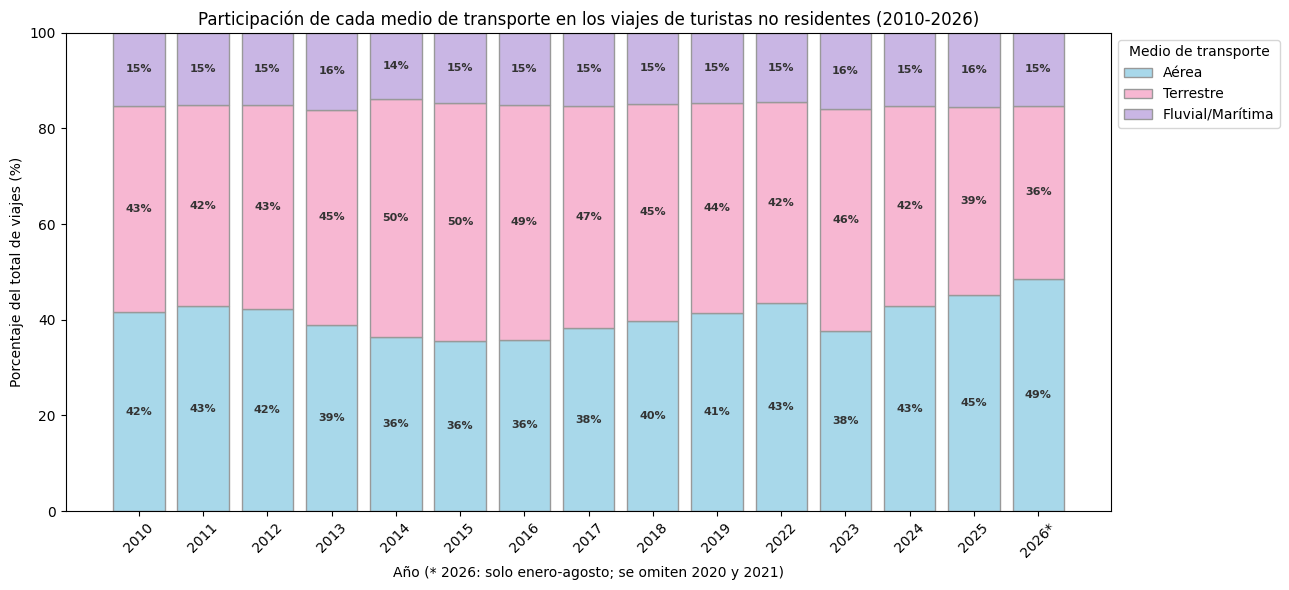

In [303]:
# 1) Viajes por año y medio de transporte (se excluyen 2020 y 2021: casi no hubo viajes terrestres y distorsionan las proporciones)
transporte = turismo.pivot_table(index='anio', columns='medio_de_transporte', values='viajes_de_turistas_no_residentes', aggfunc='sum')
transporte = transporte.drop(index=[2020, 2021])

# 2) Participación porcentual de cada medio dentro de cada año
participacion = transporte.div(transporte.sum(axis=1), axis=0) * 100
participacion = participacion[['Aérea', 'Terrestre', 'Fluvial/Marítima']]
display(participacion.round(1))

# 3) Gráfico de barras apiladas al 100%
colores = {'Aérea': '#A8D8EA', 'Terrestre': '#F7B7D2', 'Fluvial/Marítima': '#C9B6E4'}
etiquetas_anio = [f"{a}*" if a == 2026 else str(a) for a in participacion.index]

fig, ax = plt.subplots(figsize=(13, 6))
base = np.zeros(len(participacion))
for medio in participacion.columns:
    valores = participacion[medio].values
    barras = ax.bar(etiquetas_anio, valores, bottom=base.copy(), color=colores[medio], label=medio, edgecolor='#999999')
    for barra, v, b in zip(barras, valores, base):
        ax.text(barra.get_x() + barra.get_width() / 2, b + v / 2, f"{v:.0f}%", ha='center', va='center', color='#333333', fontsize=8, fontweight='bold')
    base += valores

ax.set_title('Participación de cada medio de transporte en los viajes de turistas no residentes (2010-2026)')
ax.set_xlabel('Año (* 2026: solo enero-agosto; se omiten 2020 y 2021)')
ax.set_ylabel('Porcentaje del total de viajes (%)')
ax.set_ylim(0, 100)
ax.legend(title='Medio de transporte', loc='upper left', bbox_to_anchor=(1, 1))
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('participacion_transporte.png', dpi=300)
plt.show()

####Lectura del gráfico:
Cada barra suma 100%, podemos ver cómo crece o se achica cada franja de un año a otro.

2019: aéreo 41%, terrestre 44%.

2023: el terrestre sube a 46%, el aéreo baja a 38%.

2025: el aéreo pasa al primer lugar (45% contra 39%).

2026: el aéreo llega a casi 49% y el terrestre baja a 36%.
El fluvial/marítimo se mantiene estable, alrededor del 15%.

En conclusión, el turismo no residente en Argentina presentó un comportamiento relativamente estable antes de la pandemia, seguido de una fuerte caída, una posterior recuperación y una nueva disminución en los últimos años analizados.

Aún hoy, los números siguen sin poder acercarse al años 2019, donde se registró la mayor cantidad de turistas en los 16 años que estamos analizando.